# PR 3 — Classical Image Processing → Face Detection (YuNet) → Object Detection (YOLOv8)

This notebook builds one integrated computer-vision pipeline in five tasks:

| Task | Topic | Type |
|---|---|---|
| 1 | Image I/O & Morphological operations | Classical |
| 2 | Bitwise operations & Histograms (brightness / contrast) | Classical |
| 3 | Face detection with **YuNet** (OpenCV 5.0) | Deep learning |
| 4 | Object detection with **YOLOv8n** (COCO) | Deep learning |
| 5 | Integrated pipeline, FPS benchmark, final comparison | Both |

**How to run:** open this notebook from the repository root (so `data/` and `plots/` resolve), then *Restart & Run All*.
Webcam tasks use `cv2.VideoCapture(0)`; if no webcam is found, a simulated noisy video stream is used automatically so the notebook still runs end-to-end.

# Task 1: Environment Setup, Image I/O & Morphological Operations
**Objective:** set up the environment, load images, and learn how erosion, dilation, opening and closing clean a binary mask.
**Expected output:** printed OpenCV version and array shapes, a binarisation figure, a 1×5 morphology grid, a 3×3 kernel (shape × size) grid, and a short explanation.

## 1.1 Environment setup & image loading

In [1]:
# Run once in a fresh environment:
# !pip install opencv-python==5.0.0.* opencv-contrib-python==5.0.0.* ultralytics matplotlib numpy
%matplotlib inline
import os, time
os.environ.setdefault("YOLO_VERBOSE", "False")
import cv2, numpy as np, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display, Image, Markdown
from ultralytics import YOLO

try:                                   # keep OpenCV's own console warnings out of the notebook
    cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_SILENT)
except Exception:
    pass

IMG_DIR, MODEL_DIR, PLOT_DIR = "data/images", "data/models", "plots"
FACE_MODEL = f"{MODEL_DIR}/face_detection_yunet_2023mar.onnx"
YOLO_MODEL = f"{MODEL_DIR}/yolov8n.pt"
N_FRAMES = 100                          # frames used for every real-time demo / FPS benchmark
os.makedirs(PLOT_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.labelsize": 10, "legend.fontsize": 9})
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


In [2]:
# ---------- reusable helpers (used by every task) ----------
def load(name, gray=False, max_side=1000):
    '''Read an image from data/images (BGR or gray). Very large photos are shrunk so detectors stay fast.'''
    img = cv2.imread(f"{IMG_DIR}/{name}", cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    assert img is not None, f"Could not read {IMG_DIR}/{name}"
    scale = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale < 1 else img

def show(img, title="", ax=None):
    '''Show a gray or BGR image inline (cv2.imshow does not work in Jupyter). BGR is converted to RGB.'''
    own = ax is None
    if own:
        _, ax = plt.subplots(figsize=(5, 4))
    if img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
    if own:
        plt.show()

def finish(fig, fname=None):
    '''Tidy the layout, save the figure into /plots (if a name is given) and display it.'''
    fig.tight_layout()
    if fname:
        fig.savefig(f"{PLOT_DIR}/{fname}", dpi=110, bbox_inches="tight")
    plt.show()

def grid(imgs, titles, rows, cols, fname=None, suptitle=None, cell=(3.4, 3.4)):
    '''Plot several images in a rows x cols grid.'''
    fig, axes = plt.subplots(rows, cols, figsize=(cols * cell[0], rows * cell[1]))
    axes = np.ravel(axes)
    for ax, im, t in zip(axes, imgs, titles):
        show(im, t, ax)
    for ax in axes[len(imgs):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    finish(fig, fname)

def add_salt_pepper(img, amount=0.04, seed=0):
    '''Add reproducible salt-and-pepper noise (works for gray and colour images).'''
    r = np.random.default_rng(seed).random(img.shape[:2])
    out = img.copy()
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out

gray : shape=(512, 512),  dtype=uint8
color: shape=(512, 512, 3), dtype=uint8   (height, width, 3 channels in B-G-R order)


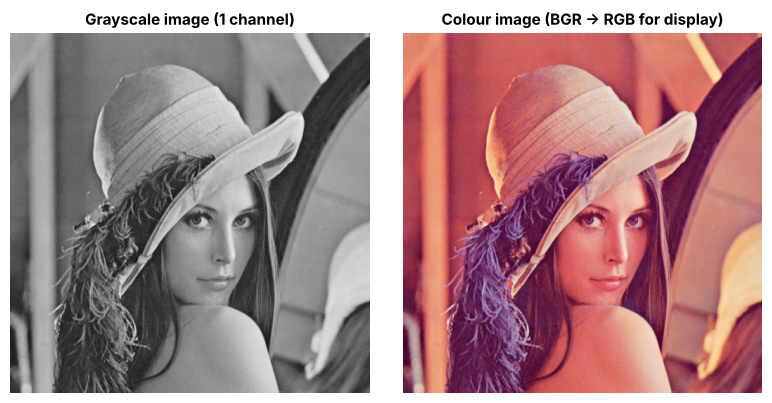

In [3]:
gray  = cv2.imread(f"{IMG_DIR}/lena.jpg", cv2.IMREAD_GRAYSCALE)
color = cv2.imread(f"{IMG_DIR}/lena.jpg", cv2.IMREAD_COLOR)
print(f"gray : shape={gray.shape},  dtype={gray.dtype}")
print(f"color: shape={color.shape}, dtype={color.dtype}   (height, width, 3 channels in B-G-R order)")
grid([gray, color], ["Grayscale image (1 channel)", "Colour image (BGR → RGB for display)"], 1, 2, cell=(4, 4))

## 1.2 Binarize a test image
The scanned music score has dark ink on white paper. Morphology treats **white = object**, so the image is inverted first and then thresholded at 127. Synthetic salt-and-pepper noise is added to create a realistic noisy mask for the experiments.

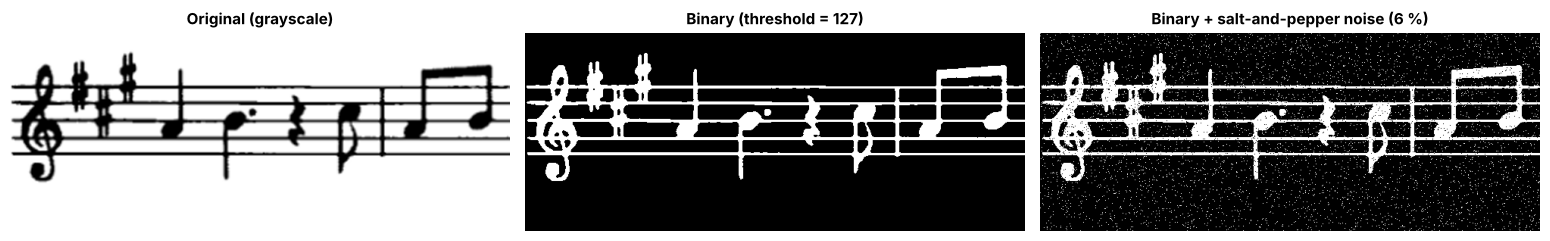

In [4]:
score_bgr = load("notes.png")[:, :330]                                   # crop: clef + first notes
score = cv2.resize(cv2.cvtColor(score_bgr, cv2.COLOR_BGR2GRAY), None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
_, binary = cv2.threshold(cv2.bitwise_not(score), 127, 255, cv2.THRESH_BINARY)   # ink → white (255)
noisy = add_salt_pepper(binary, amount=0.06)
grid([score, binary, noisy], ["Original (grayscale)", "Binary (threshold = 127)", "Binary + salt-and-pepper noise (6 %)"],
     1, 3, cell=(5.2, 2.6))

## 1.3 Apply the four morphological operations
5×5 rectangular kernel applied to the noisy binary mask.

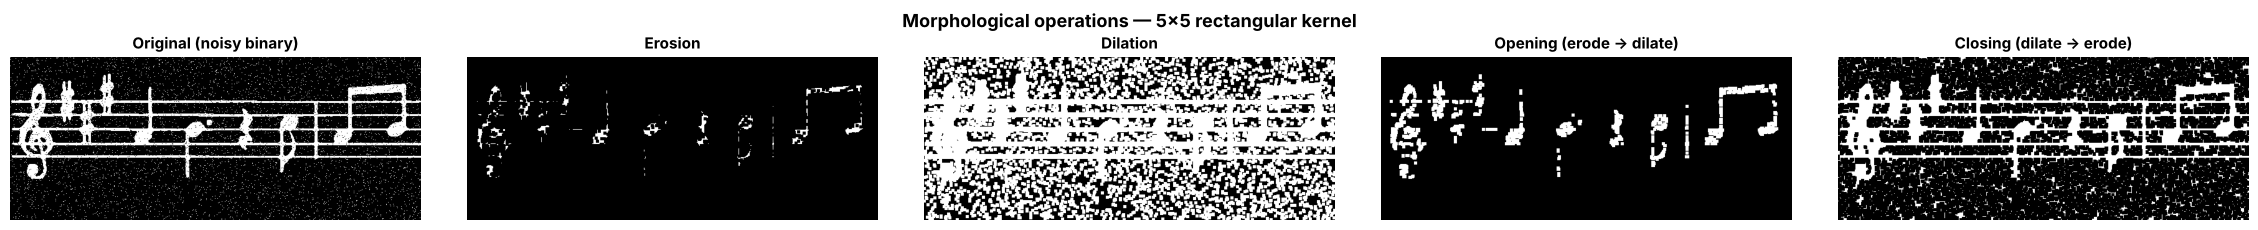

In [5]:
kernel = np.ones((5, 5), np.uint8)
ops = {"Original (noisy binary)": noisy,
       "Erosion":  cv2.erode(noisy, kernel),
       "Dilation": cv2.dilate(noisy, kernel),
       "Opening (erode → dilate)":  cv2.morphologyEx(noisy, cv2.MORPH_OPEN,  kernel),
       "Closing (dilate → erode)":  cv2.morphologyEx(noisy, cv2.MORPH_CLOSE, kernel)}
grid(list(ops.values()), list(ops), 1, 5, "morphology_grid.png", suptitle="Morphological operations — 5×5 rectangular kernel", cell=(4.6, 2.3))

## 1.4 Kernel shape & size comparison
Each cell applies **opening followed by closing** (opening removes white specks, closing fills black specks) with a different structuring element. The title shows the *error*: the percentage of pixels that differ from the clean binary image — it grows both when noise survives and when the object outline is eroded.

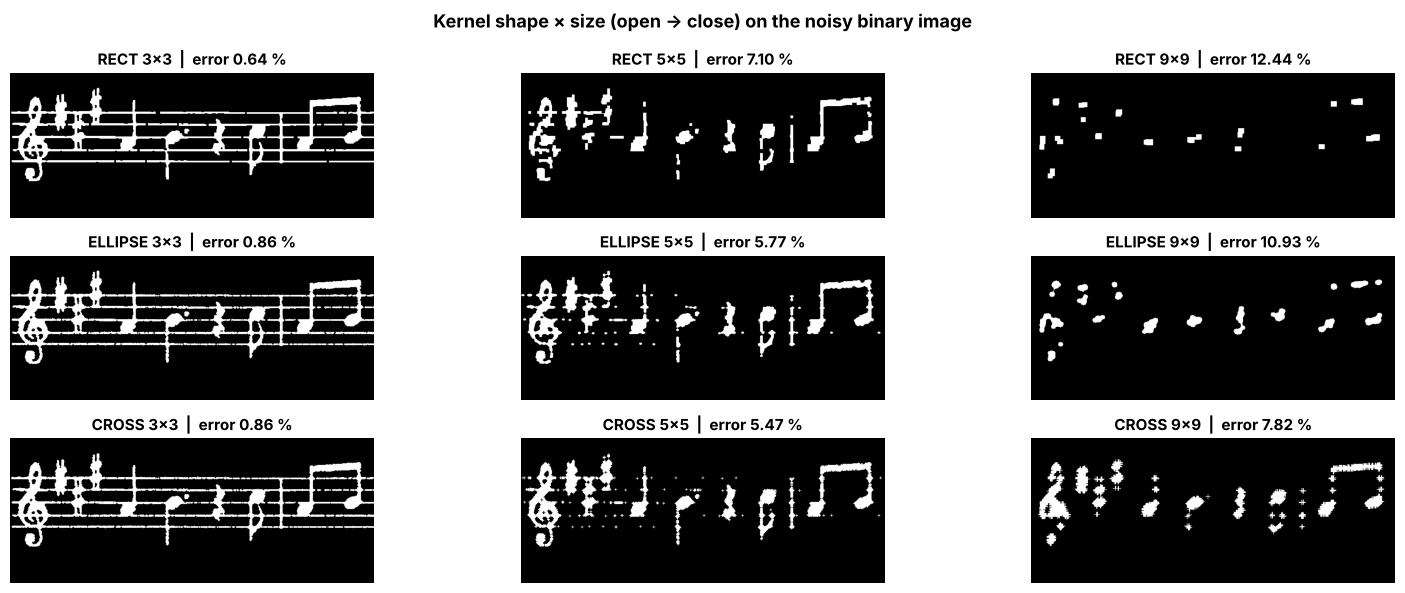

Noisy input error: 3.00 %   →   best kernel: RECT 3×3 (error 0.64 %)


In [6]:
shapes = {"RECT": cv2.MORPH_RECT, "ELLIPSE": cv2.MORPH_ELLIPSE, "CROSS": cv2.MORPH_CROSS}
sizes = (3, 5, 9)

def denoise(img, shape, k):
    '''Opening then closing with a k x k structuring element of the given shape.'''
    se = cv2.getStructuringElement(shape, (k, k))
    return cv2.morphologyEx(cv2.morphologyEx(img, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)

cleaned = {(n, k): denoise(noisy, s, k) for n, s in shapes.items() for k in sizes}
error = {key: 100 * np.mean(im != binary) for key, im in cleaned.items()}
grid(list(cleaned.values()), [f"{n} {k}×{k}  |  error {error[(n, k)]:.2f} %" for n, k in cleaned], 3, 3,
     "kernel_comparison.png", suptitle="Kernel shape × size (open → close) on the noisy binary image", cell=(5.2, 2.0))
best = min(error, key=error.get)
print(f"Noisy input error: {100 * np.mean(noisy != binary):.2f} %   →   best kernel: {best[0]} {best[1]}×{best[1]} (error {error[best]:.2f} %)")

## 1.5 WHY morphology works
**Kernel result (from the 3×3 grid in 1.4).** The best combination is **RECT 3×3** (error 0.64 %): it removes almost all salt-and-pepper noise while the staff lines and note outlines stay intact. ELLIPSE and CROSS at 3×3 are the same 4-neighbour shape, so they score identically (0.86 %) and leave a few diagonal specks. At 5×5 and 9×9 the kernel is wider than the thin strokes, so opening erases staff lines and breaks the notes (error 5–12 %) — a bigger kernel removes more noise but also erodes the object outline. Rule: choose the smallest kernel that is larger than the noise but smaller than the thinnest feature you want to keep.

* **Erosion = local *minimum* filter.** Every output pixel becomes the minimum of the neighbourhood under the kernel, so white regions shrink, tiny bright specks vanish and thin white strokes (the staff lines of our score) disappear.
* **Dilation = local *maximum* filter.** Every output pixel becomes the maximum of its neighbourhood, so white regions grow, small dark gaps/holes are filled and nearby parts are joined.
* **Opening = erosion → dilation.** The erosion deletes small bright noise; the dilation then restores the surviving objects to their original size, so noise is removed while the overall shape and size are preserved.
* **Closing = dilation → erosion.** The dilation fills small holes and gaps; the erosion shrinks the object back, so holes are filled without the object growing.

**Real scenarios before passing a mask to a downstream detector**
* **Opening:** a background-subtraction mask from a night-time security camera is full of isolated white speckles (sensor noise, rain). Opening removes them so the detector/blob-finder is not triggered by dozens of tiny false regions.
* **Closing:** a person's silhouette mask has holes and cracks because their clothes resemble the background. Closing fills them so the person becomes *one* solid blob and one clean bounding box instead of several fragments.

# Task 2: Bitwise Operations & Image Histograms
**Objective:** use bitwise logic to combine masks and images, and use histograms to diagnose brightness and contrast.
**Expected output:** a 2×3 bitwise grid, a masked-overlay before/after figure, gray and B/G/R histograms, and a brightness/contrast comparison with histograms.

## 2.1 Bitwise AND / OR / XOR / NOT

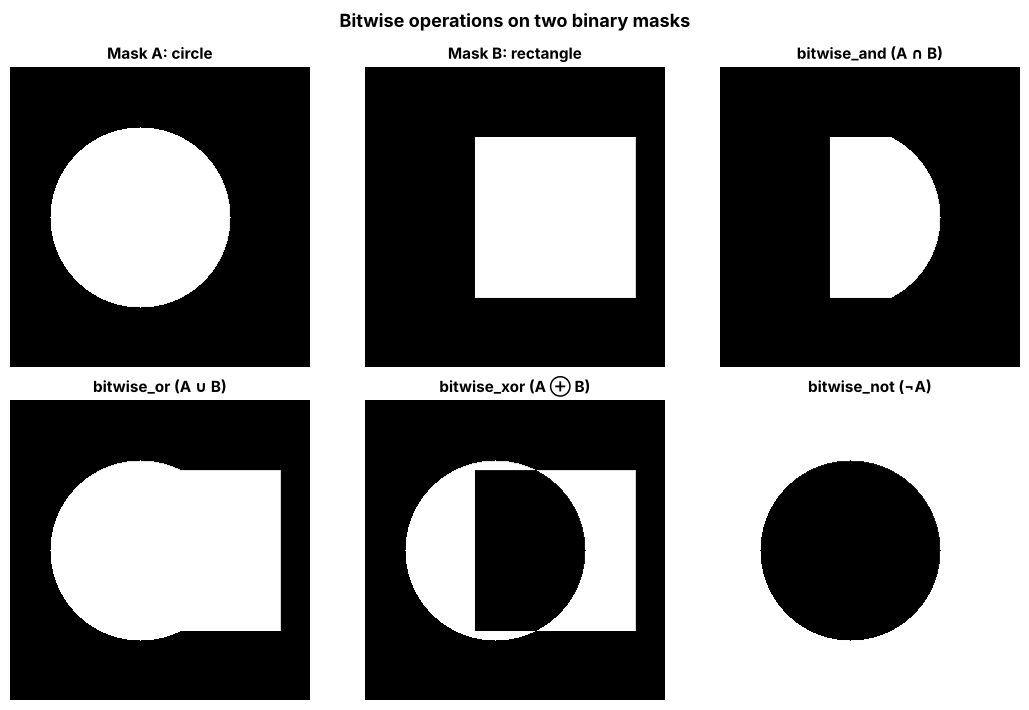

In [7]:
circle = cv2.circle(np.zeros((300, 300), np.uint8), (130, 150), 90, 255, -1)               # Mask A
rect   = cv2.rectangle(np.zeros((300, 300), np.uint8), (110, 70), (270, 230), 255, -1)    # Mask B
bit_ops = {"bitwise_and (A ∩ B)": cv2.bitwise_and(circle, rect),
           "bitwise_or (A ∪ B)":  cv2.bitwise_or(circle, rect),
           "bitwise_xor (A ⊕ B)": cv2.bitwise_xor(circle, rect),
           "bitwise_not (¬A)":    cv2.bitwise_not(circle)}
grid([circle, rect, *bit_ops.values()], ["Mask A: circle", "Mask B: rectangle", *bit_ops], 2, 3,
     "bitwise_operations.png", suptitle="Bitwise operations on two binary masks", cell=(3.6, 3.6))

## 2.2 Applied use-case: masked overlay
`bitwise_and` with a circular ROI mask extracts only the region of interest; `bitwise_or` composites a logo (watermark) onto the photo after the logo's footprint is cleared from the background.

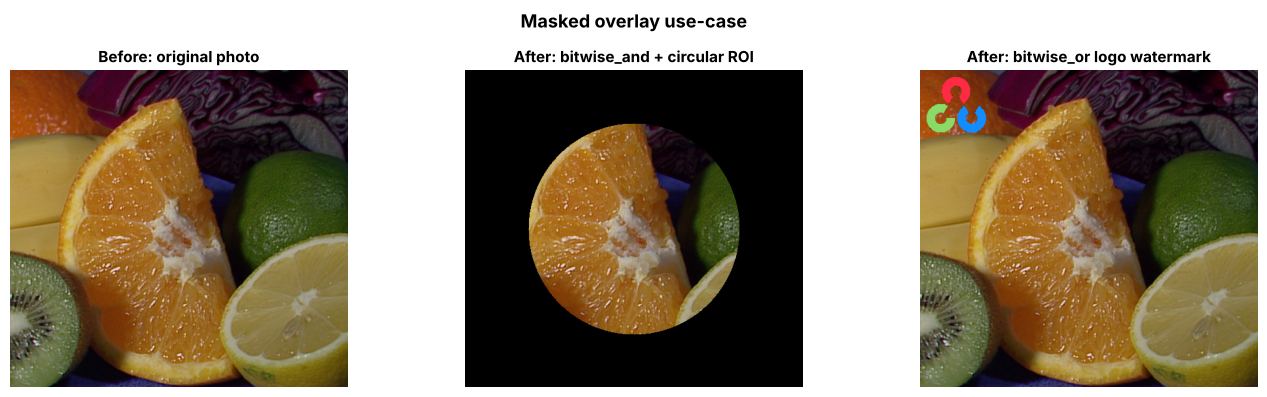

In [8]:
photo = load("fruits.jpg")
h, w = photo.shape[:2]

# (a) extract a circular region of interest
roi_mask = cv2.circle(np.zeros((h, w), np.uint8), (w // 2, h // 2), min(h, w) // 3, 255, -1)
roi_only = cv2.bitwise_and(photo, photo, mask=roi_mask)

# (b) watermark: clear the logo footprint in the photo, keep only the logo pixels, then OR them together
logo = cv2.resize(load("opencv_logo.png"), (90, 120))
lh, lw = logo.shape[:2]
logo_mask = cv2.threshold(cv2.cvtColor(logo, cv2.COLOR_BGR2GRAY), 10, 255, cv2.THRESH_BINARY)[1]
corner = photo[10:10 + lh, 10:10 + lw]
cleared = cv2.bitwise_and(corner, corner, mask=cv2.bitwise_not(logo_mask))
logo_px = cv2.bitwise_and(logo, logo, mask=logo_mask)
marked = photo.copy()
marked[10:10 + lh, 10:10 + lw] = cv2.bitwise_or(cleared, logo_px)

grid([photo, roi_only, marked], ["Before: original photo", "After: bitwise_and + circular ROI", "After: bitwise_or logo watermark"],
     1, 3, "masked_overlay.png", suptitle="Masked overlay use-case", cell=(4.6, 4))

## 2.3 Grayscale & per-channel colour histograms

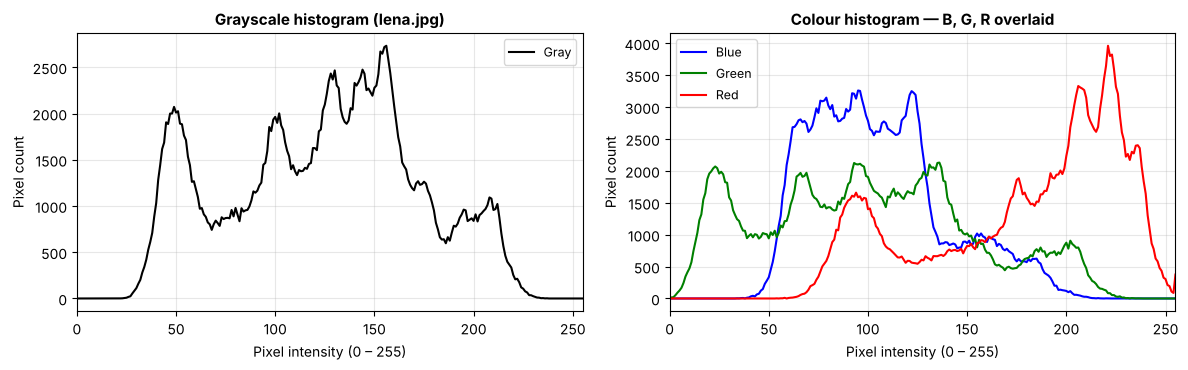

In [9]:
def plot_hist(ax, img, title):
    '''Gray image → one curve; BGR image → overlaid blue / green / red curves (cv2.calcHist per channel).'''
    channels = [("Gray", "black")] if img.ndim == 2 else [("Blue", "b"), ("Green", "g"), ("Red", "r")]
    for i, (label, col) in enumerate(channels):
        ax.plot(cv2.calcHist([img], [i], None, [256], [0, 256]), color=col, label=label)
    ax.set(title=title, xlabel="Pixel intensity (0 – 255)", ylabel="Pixel count", xlim=(0, 255))
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_hist(axes[0], gray,  "Grayscale histogram (lena.jpg)")
plot_hist(axes[1], color, "Colour histogram — B, G, R overlaid")
finish(fig, "histograms_gray_color.png")

## 2.4 Brightness & contrast adjustment
`cv2.convertScaleAbs(img, alpha, beta)` computes `|alpha·pixel + beta|` clipped to 0–255. The mean and standard deviation in each title make the effect measurable.

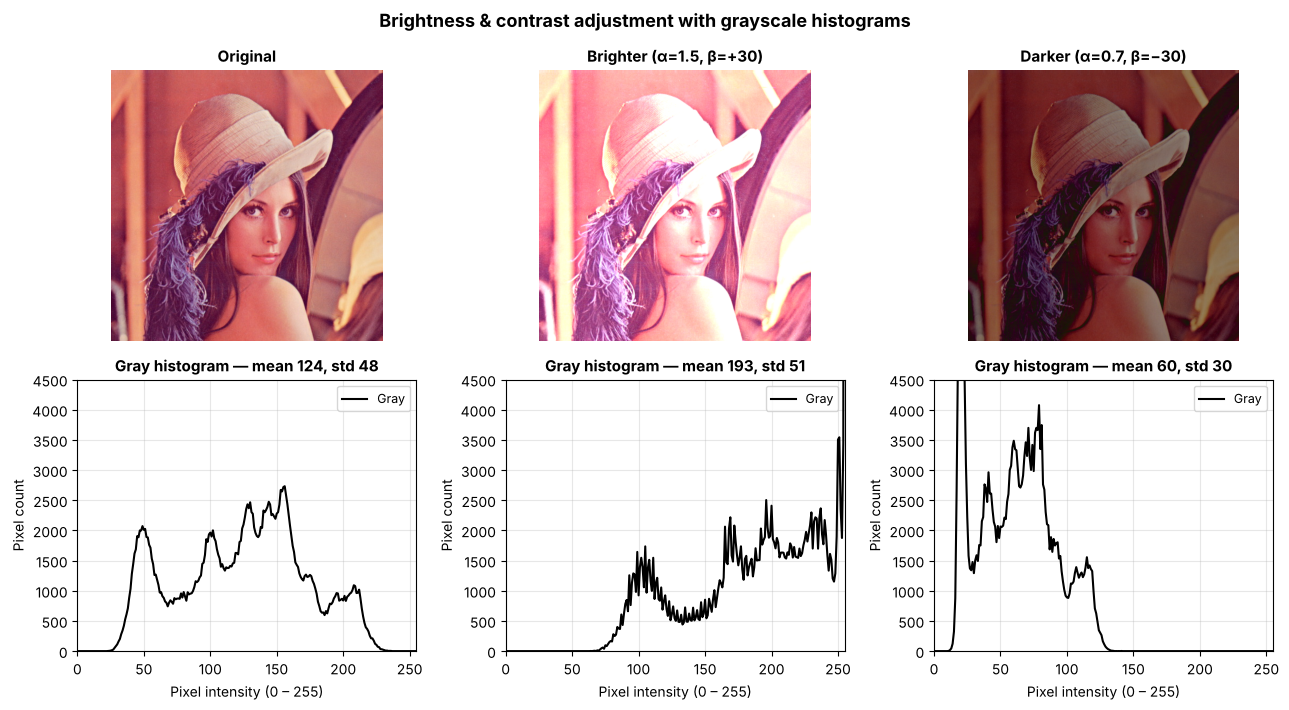

In [10]:
versions = {"Original": color,
            "Brighter (α=1.5, β=+30)": cv2.convertScaleAbs(color, alpha=1.5, beta=30),
            "Darker (α=0.7, β=−30)":   cv2.convertScaleAbs(color, alpha=0.7, beta=-30)}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for col, (name, im) in enumerate(versions.items()):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    show(im, name, axes[0, col])
    plot_hist(axes[1, col], g, f"Gray histogram — mean {g.mean():.0f}, std {g.std():.0f}")
    axes[1, col].set_ylim(0, 4500)
fig.suptitle("Brightness & contrast adjustment with grayscale histograms", fontsize=13, fontweight="bold")
finish(fig, "histogram_comparison.png")

## 2.5 WHY alpha/beta and histograms matter
The adjustment is `new_pixel = alpha · pixel + beta`.

* **alpha (contrast gain)** multiplies every pixel, so it *stretches* (alpha > 1) or *compresses* (alpha < 1) the histogram around its mean — in the figure the standard deviation falls for α=0.7 (std 48 → 30) and rises only slightly for α=1.5 because many bright pixels are clipped at 255.
* **beta (brightness offset)** is added to every pixel, so it *slides* the whole histogram right (β > 0) or left (β < 0) without changing its shape — the mean moves accordingly.
* **Reading a histogram:** a *narrow* histogram means low contrast (washed-out image). A histogram *piled up at 0 or 255* means clipping — under-exposure (lost shadows) or over-exposure (lost highlights). The brightened version above shows a spike at 255 (it runs off the top of the chart) where information was destroyed.
* **Why it matters for the detectors:** YuNet and YOLO see the pixel values directly. A histogram check before detection tells us whether a frame needs correction (e.g. a dark, narrow histogram from a badly lit camera) and warns us when over-correction would clip faces or objects into flat white/black regions that no detector can recover.

# Task 3: Face Detection with YuNet (OpenCV 5.0)
**Objective:** detect faces, 5 facial landmarks and confidence scores with the pretrained YuNet network, in images and in real time.
**Expected output:** annotated static images (frontal, side-profile, sunglasses), a live webcam demo with FPS, a score-threshold experiment and a face-blur privacy filter.

## 3.1 Load the YuNet face detector

In [11]:
if not os.path.exists(FACE_MODEL):          # fresh clone without the weights → fetch them from the OpenCV Zoo
    import urllib.request
    urllib.request.urlretrieve("https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/"
                               "face_detection_yunet_2023mar.onnx", FACE_MODEL)

def get_face_detector(score=0.9):
    return cv2.FaceDetectorYN_create(FACE_MODEL, "", (320, 320), score_threshold=score)

def detect_faces(detector, img):
    '''Match the detector input size to the image, run YuNet, return an (N, 15) array:
       x, y, w, h, 5 landmarks (x, y) and the confidence score.'''
    h, w = img.shape[:2]
    detector.setInputSize((w, h))
    _, faces = detector.detect(img)
    return np.empty((0, 15), np.float32) if faces is None else faces

def draw_faces(img, faces, color=(0, 255, 0)):
    '''Draw box, 5 landmarks (red) and score for every detected face.'''
    out, t = img.copy(), max(1, round(max(img.shape[:2]) / 400))
    for f in faces:
        x, y, bw, bh = f[:4].astype(int)
        cv2.rectangle(out, (x, y), (x + bw, y + bh), color, t)
        for lx, ly in f[4:14].reshape(5, 2).astype(int):
            cv2.circle(out, (lx, ly), t + 1, (0, 0, 255), -1)
        cv2.putText(out, f"{f[14]:.2f}", (x, max(y - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.45 * t + 0.3, color, t)
    return out

face_det = get_face_detector(score=0.9)
faces = detect_faces(face_det, load("lena.jpg"))
print("Columns per face: box(4) + landmarks(10) + score(1) =", faces.shape[1])
print("lena.jpg → box/score:", faces[0, :4].astype(int), round(float(faces[0, 14]), 3))

Columns per face: box(4) + landmarks(10) + score(1) = 15
lena.jpg → box/score: [207 182 145 206] 0.909


## 3.2 Detect on static images
Four images with varied pose, lighting and face count: two people, one frontal and one in side-profile and shouting (`zidane`), a frontal portrait (`lena`), a face wearing sunglasses (partial occlusion) and a head turned and tilted up. Threshold = 0.9, so the side-profile face in `zidane` is expected to be missed.

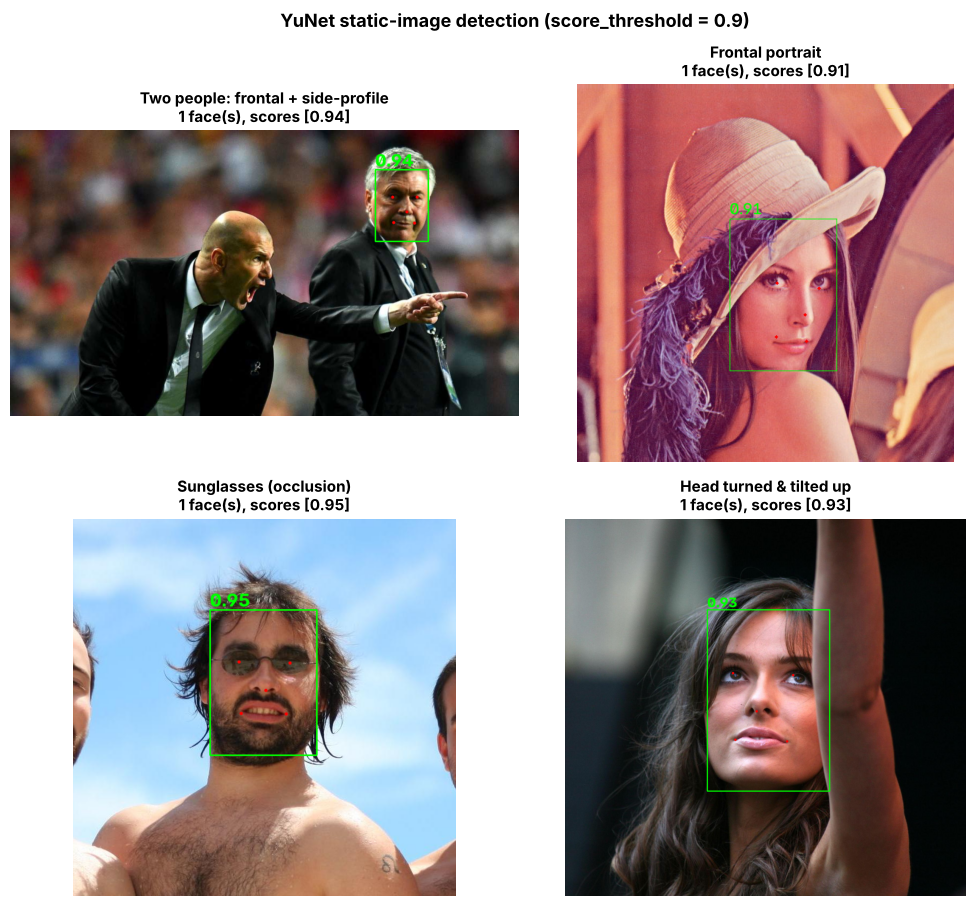

In [12]:
FACE_IMAGES = ["zidane.jpg", "lena.jpg", "face_sunglasses.jpg", "face_side_profile.jpg"]
LABELS = ["Two people: frontal + side-profile", "Frontal portrait", "Sunglasses (occlusion)", "Head turned & tilted up"]
shots, titles = [], []
for name, label in zip(FACE_IMAGES, LABELS):
    img = load(name)
    f = detect_faces(face_det, img)
    shots.append(draw_faces(img, f))
    titles.append(f"{label}\n{len(f)} face(s)" + (f", scores {[round(float(s), 2) for s in f[:, 14]]}" if len(f) else " detected at 0.9"))
grid(shots, titles, 2, 2, "face_detection_comparison.png", suptitle="YuNet static-image detection (score_threshold = 0.9)", cell=(5.2, 4.6))

## 3.3 Real-time detection on webcam
The helpers below are shared by every real-time task (3.3, 4.2, 5.1): `stream()` yields frames from the webcam (or a simulated noisy stream if no webcam exists), `run_stream()` processes and displays them live and returns the average FPS.

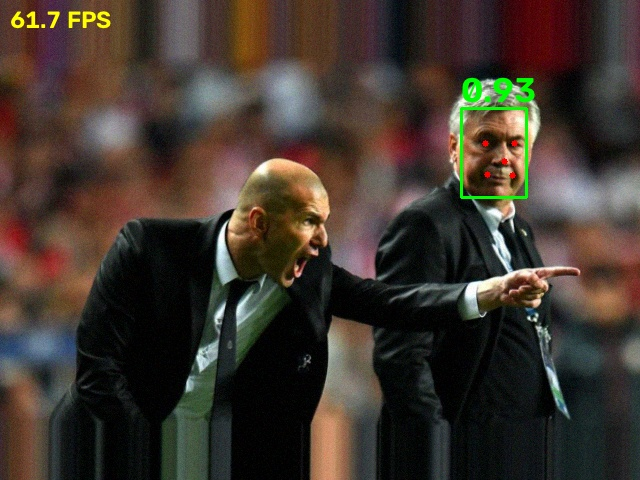

Frame source: SIMULATED stream (no webcam found) — photo with camera motion + sensor noise


YuNet real-time face detection: 100 frames processed, average 61.7 FPS


In [13]:
def stream(n=N_FRAMES, size=(640, 480)):
    '''Yield n BGR frames from the webcam. If no webcam is available, simulate a noisy moving-camera stream.'''
    cap = cv2.VideoCapture(0)
    if cap.isOpened():
        print("Frame source: WEBCAM")
        for _ in range(n):
            ok, frame = cap.read()
            if not ok:
                break
            yield cv2.resize(frame, size)
        cap.release()
        return
    print("Frame source: SIMULATED stream (no webcam found) — photo with camera motion + sensor noise")
    base = cv2.resize(load("zidane.jpg"), (size[0], size[0] * 9 // 16))
    pad = (size[1] - base.shape[0]) // 2
    base = cv2.copyMakeBorder(base, pad, size[1] - base.shape[0] - pad, 0, 0, cv2.BORDER_REPLICATE)
    rng = np.random.default_rng(0)
    for i in range(n):
        M = cv2.getRotationMatrix2D((size[0] / 2, size[1] / 2), 1.5 * np.sin(i / 10), 1 + 0.04 * np.sin(i / 14))
        M[0, 2] += 14 * np.sin(i / 8)
        frame = cv2.warpAffine(base, M, size, borderMode=cv2.BORDER_REPLICATE)
        yield np.clip(frame + rng.normal(0, 6, frame.shape), 0, 255).astype(np.uint8)

def run_stream(process, title, n=N_FRAMES, save=None):
    '''Apply process(frame) → annotated frame to a live stream, show it (refreshing in place) and return the average FPS.'''
    handle = display(Markdown(f"▶ *{title} …*"), display_id=True)
    spent, count, out = 0.0, 0, None
    for frame in stream(n):
        t0 = time.perf_counter()
        out = process(frame)
        spent += time.perf_counter() - t0
        count += 1
        cv2.putText(out, f"{count / spent:.1f} FPS", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
        if count % 5 == 0 or count == 1:
            handle.update(Image(data=cv2.imencode(".jpg", out)[1].tobytes()))
    handle.update(Image(data=cv2.imencode(".jpg", out)[1].tobytes()))
    if save:
        cv2.imwrite(f"{PLOT_DIR}/{save}", out)
    print(f"{title}: {count} frames processed, average {count / spent:.1f} FPS")
    return count / spent

fps_face_live = run_stream(lambda f: draw_faces(f, detect_faces(face_det, f)), "YuNet real-time face detection", save="face_webcam_frame.png")

## 3.4 Score-threshold experiment & privacy-blur use-case

image                     thr=0.5   thr=0.7   thr=0.9   
zidane.jpg                3         3         1         


bus.jpg                   2         2         2         
face_side_profile.jpg     1         1         1         


street.png                0         0         0         


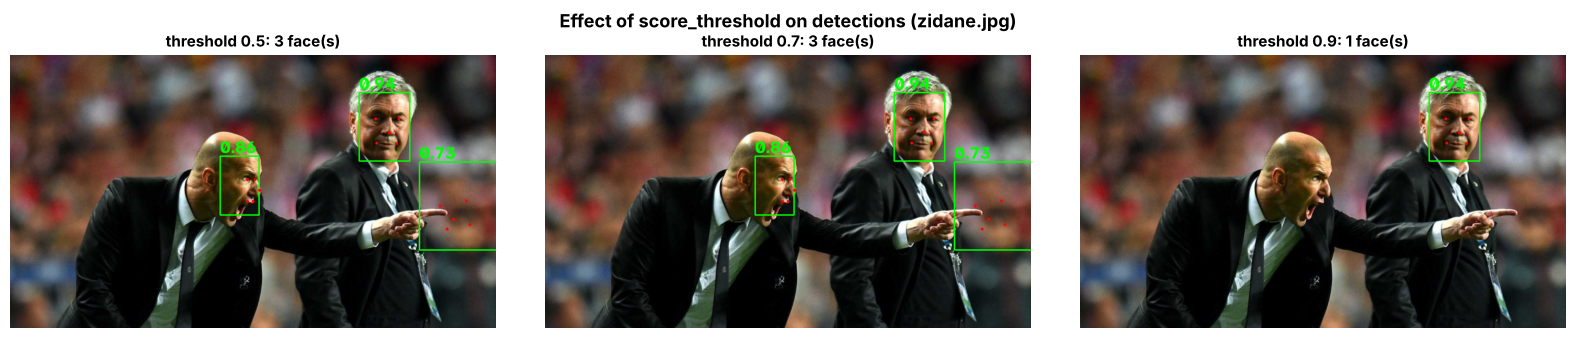

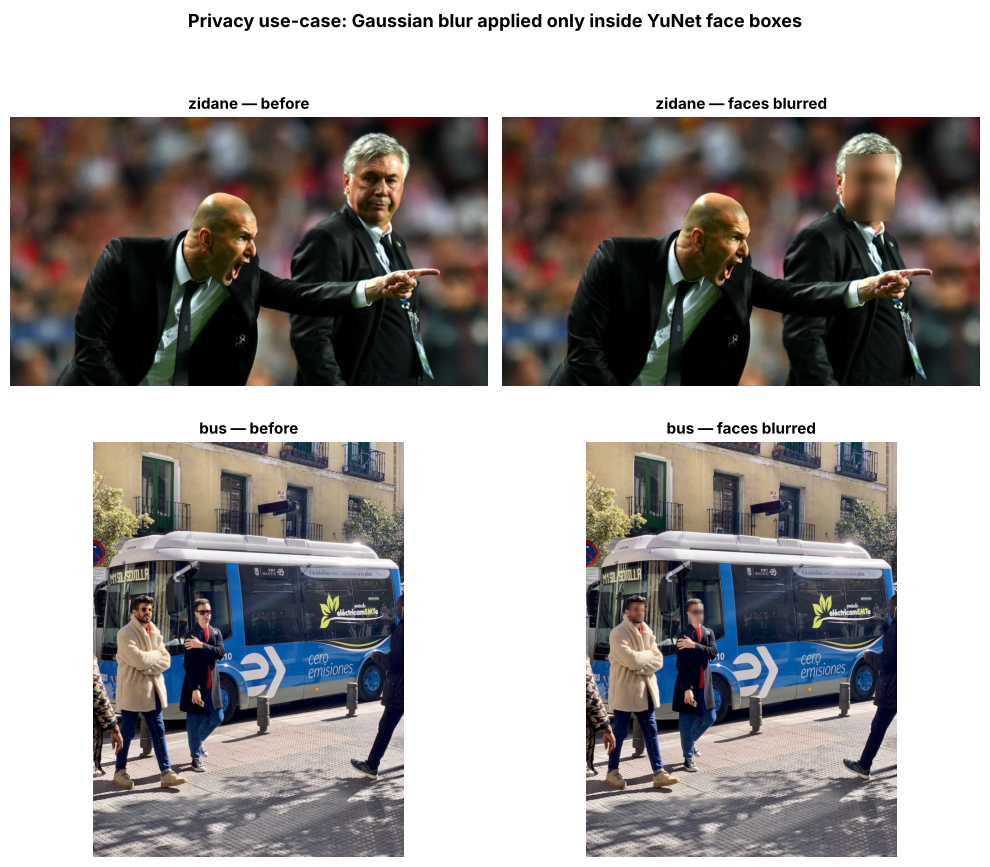

In [14]:
THRESHOLDS = (0.5, 0.7, 0.9)
detectors = {t: get_face_detector(t) for t in THRESHOLDS}
exp_images = ["zidane.jpg", "bus.jpg", "face_side_profile.jpg", "street.png"]
print(f"{'image':26s}" + "".join(f"thr={t:<6}" for t in THRESHOLDS))
for name in exp_images:
    img = load(name)
    print(f"{name:26s}" + "".join(f"{len(detect_faces(detectors[t], img)):<10d}" for t in THRESHOLDS))

img = load("zidane.jpg")
faces_t = {t: detect_faces(detectors[t], img) for t in THRESHOLDS}
grid([draw_faces(img, f) for f in faces_t.values()], [f"threshold {t}: {len(f)} face(s)" for t, f in faces_t.items()], 1, 3,
     "face_threshold_experiment.png", suptitle="Effect of score_threshold on detections (zidane.jpg)", cell=(5.4, 3.4))
def blur_faces(img, faces):
    '''Gaussian-blur only inside each detected face box (anonymisation).'''
    out = img.copy()
    for f in faces:
        x, y, bw, bh = np.clip(f[:4].astype(int), 0, None)
        roi = out[y:y + bh, x:x + bw]
        k = (max(bw, bh) // 2) | 1                       # odd kernel proportional to the face size
        out[y:y + bh, x:x + bw] = cv2.GaussianBlur(roi, (k, k), 0)
    return out

privacy = [load(n) for n in ("zidane.jpg", "bus.jpg")]
pairs = [im for img in privacy for im in (img, blur_faces(img, detect_faces(face_det, img)))]
grid(pairs, ["zidane — before", "zidane — faces blurred", "bus — before", "bus — faces blurred"], 2, 2,
     "face_privacy_blur.png", suptitle="Privacy use-case: Gaussian blur applied only inside YuNet face boxes", cell=(5, 4.4))

## 3.5 WHY YuNet
**YuNet** is a compact, modern CNN-based face detector and the recommended default shipped with OpenCV 5.0 through `cv2.FaceDetectorYN`. It is trained on diverse "in-the-wild" faces, so it generalises to side views, partial occlusion (sunglasses) and small or blurry faces, and in a **single forward pass** it returns the box, a **confidence score** and **5 facial landmarks** (two eyes, nose tip, two mouth corners). Because the network is tiny (≈ 230 KB ONNX file) it runs in real time on a CPU.

**The `score_threshold` trade-off.** Every candidate face gets a score; only candidates above the threshold are kept.
* **Low threshold (0.5 / 0.7):** fewer missed faces — the shouting side-profile man in `zidane` is recovered (score 0.86) — but a low-confidence **false positive** also appears (score 0.73, a box on the blurred crowd at the right edge).
* **High threshold (0.9):** the false positive disappears, but the hard side-profile face is **missed** — only 1 of the 2 faces remains.

**What I would pick:** for a **real-time security camera** I would use a *high-to-medium* threshold (≈ 0.8–0.9): a false alarm every few seconds is costly and the camera sees many frames, so a face missed in one frame will be caught in the next. For an **offline photo-tagging tool** I would use a *lower* threshold (≈ 0.5–0.6): every photo is processed once, a missed face is a permanent miss, and a human can cheaply discard a wrong suggestion.

# Task 4: Object Detection with YOLO
**Objective:** detect everyday objects with the pretrained YOLOv8-nano (COCO, 80 classes) and study how its thresholds and speed behave.
**Expected output:** annotated static images, a live webcam demo with FPS, confidence/IoU threshold plots with a duplicate-box (NMS) example, and a per-class detection bar chart.

## 4.1 Load pretrained YOLOv8 & run on static images

zidane.jpg        → person ×2, tie ×1
bus.jpg           → bus ×1, person ×3, stop sign ×1
street.png        → car ×2, person ×1, traffic light ×3


dog_bicycle.png   → dog ×1, bicycle ×1, truck ×1, car ×1


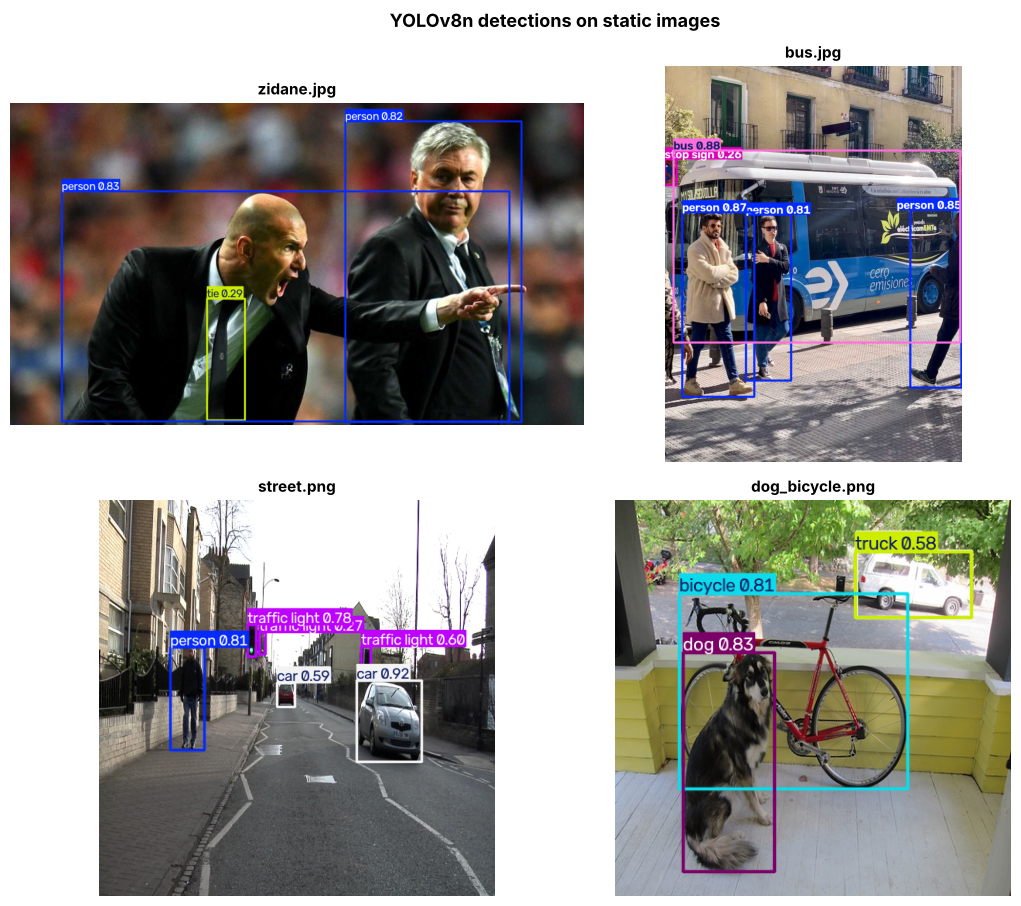

In [15]:
model = YOLO(YOLO_MODEL if os.path.exists(YOLO_MODEL) else "yolov8n.pt")      # auto-downloads if the weights are missing

def yolo_detect(img, **kw):
    '''Run YOLOv8n on one image/frame and return the Results object.'''
    return model(img, verbose=False, **kw)[0]

def class_names(res):
    return [res.names[int(c)] for c in res.boxes.cls]

YOLO_IMAGES = ["zidane.jpg", "bus.jpg", "street.png", "dog_bicycle.png"]
plots = []
for name in YOLO_IMAGES:
    res = yolo_detect(load(name))
    plots.append(res.plot())                                   # boxes + class labels + confidence scores (BGR)
    print(f"{name:18s}→ " + ", ".join(f"{k} ×{v}" for k, v in Counter(class_names(res)).items()))
grid(plots, YOLO_IMAGES, 2, 2, "yolo_detections.png", suptitle="YOLOv8n detections on static images", cell=(5.6, 4.6))

## 4.2 Real-time YOLO on webcam

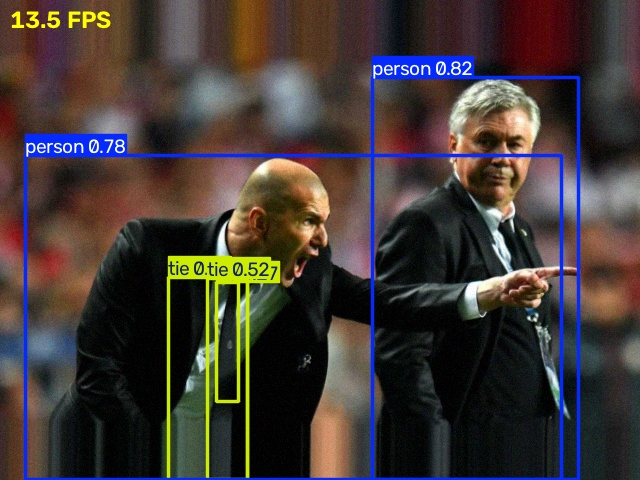

Frame source: SIMULATED stream (no webcam found) — photo with camera motion + sensor noise


YOLOv8n real-time object detection: 100 frames processed, average 13.5 FPS


In [16]:
fps_yolo_live = run_stream(lambda f: yolo_detect(f).plot(), "YOLOv8n real-time object detection", save="yolo_webcam_frame.png")

## 4.3 Confidence & IoU threshold tuning
Total number of retained boxes for each setting on the four test images. `iou` is the **NMS overlap limit**: two same-class boxes that overlap more than this value are merged into one.

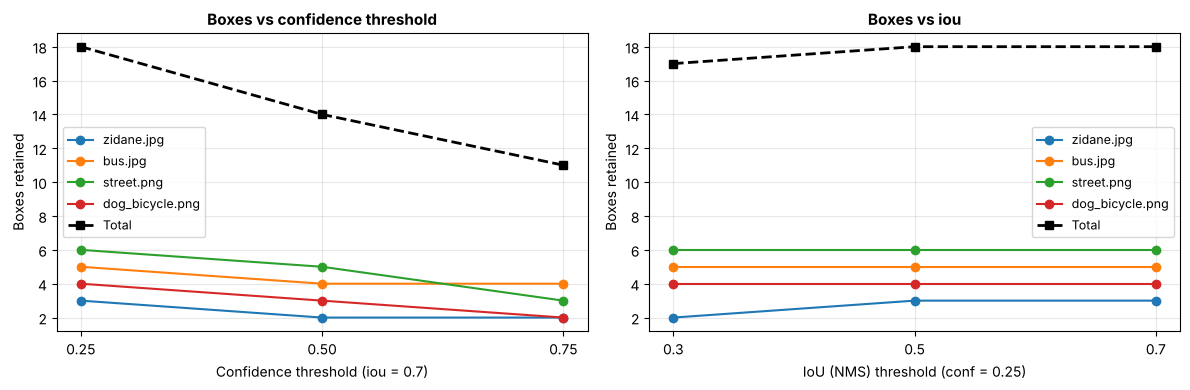

Total boxes — conf: {0.25: np.int64(18), 0.5: np.int64(14), 0.75: np.int64(11)} | iou: {0.3: np.int64(17), 0.5: np.int64(18), 0.7: np.int64(18)}


In [17]:
test_imgs = {n: load(n) for n in YOLO_IMAGES}
CONFS, IOUS = (0.25, 0.5, 0.75), (0.3, 0.5, 0.7)
vs_conf = {n: [len(yolo_detect(im, conf=c).boxes) for c in CONFS] for n, im in test_imgs.items()}   # iou fixed at default 0.7
vs_iou  = {n: [len(yolo_detect(im, iou=i).boxes) for i in IOUS]  for n, im in test_imgs.items()}   # conf fixed at default 0.25

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, xs, xlabel in ((axes[0], vs_conf, CONFS, "Confidence threshold (iou = 0.7)"), (axes[1], vs_iou, IOUS, "IoU (NMS) threshold (conf = 0.25)")):
    for n, ys in data.items():
        ax.plot(xs, ys, marker="o", label=n)
    ax.plot(xs, np.sum(list(data.values()), axis=0), "k--", marker="s", lw=2, label="Total")
    ax.set(xlabel=xlabel, ylabel="Boxes retained", xticks=xs, title="Boxes vs " + xlabel.split(" (")[0].lower())
    ax.legend()
finish(fig, "yolo_threshold_tuning.png")
print("Total boxes — conf:", dict(zip(CONFS, np.sum(list(vs_conf.values()), axis=0))), "| iou:", dict(zip(IOUS, np.sum(list(vs_iou.values()), axis=0))))

**Duplicate-box example.** Before Non-Max Suppression every object is predicted by several neighbouring grid cells, giving many overlapping boxes for the same object. NMS keeps the best one and removes the rest *if their overlap is above the IoU threshold*. So duplicates survive when the threshold is **too permissive** (high; `iou=1.0` switches NMS off completely), while a **very low** value suppresses so aggressively that neighbouring objects of the same class can be wrongly merged. The three panels below show both ends on the image where the effect is strongest.

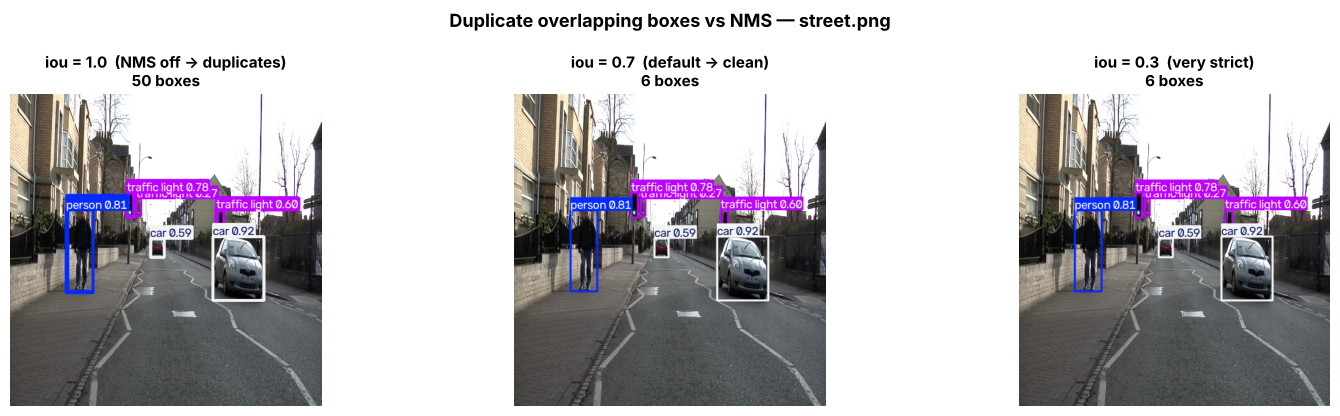

In [18]:
n_boxes = lambda im, i: len(yolo_detect(im, iou=i).boxes)
dup_name = max(test_imgs, key=lambda n: n_boxes(test_imgs[n], 1.0) - n_boxes(test_imgs[n], 0.7))
variants = {"iou = 1.0  (NMS off → duplicates)": 1.0, "iou = 0.7  (default → clean)": 0.7, "iou = 0.3  (very strict)": 0.3}
grid([yolo_detect(test_imgs[dup_name], iou=i).plot() for i in variants.values()],
     [f"{k}\n{n_boxes(test_imgs[dup_name], i)} boxes" for k, i in variants.items()], 1, 3,
     "yolo_nms_duplicates.png", suptitle=f"Duplicate overlapping boxes vs NMS — {dup_name}", cell=(5.2, 4.2))

## 4.4 Per-class detection summary
Tally of every detection over eight real photos (the four test images plus `fruits`, `lena`, `face_sunglasses`, `face_side_profile`).

zidane.jpg            → person ×2, tie ×1
bus.jpg               → bus ×1, person ×3, stop sign ×1
street.png            → car ×2, person ×1, traffic light ×3
dog_bicycle.png       → dog ×1, bicycle ×1, truck ×1, car ×1
fruits.jpg            → orange ×3
lena.jpg              → person ×1, umbrella ×1
face_sunglasses.jpg   → person ×2
face_side_profile.jpg → person ×1


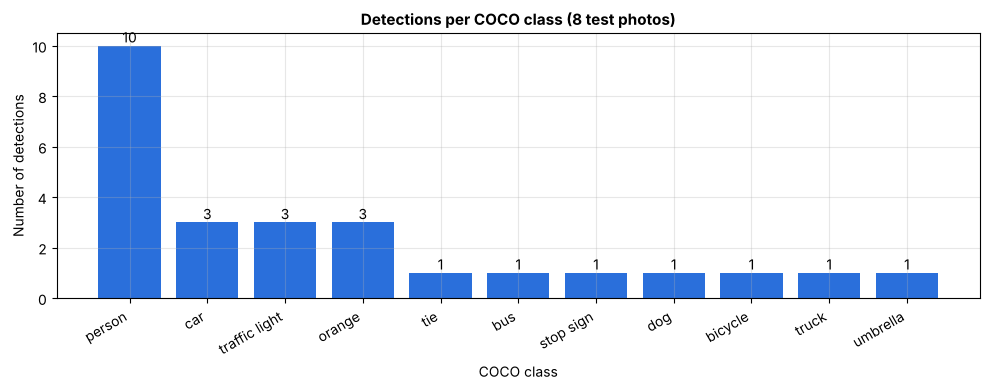

In [19]:
TALLY_IMAGES = YOLO_IMAGES + ["fruits.jpg", "lena.jpg", "face_sunglasses.jpg", "face_side_profile.jpg"]
per_image = {n: Counter(class_names(yolo_detect(load(n)))) for n in TALLY_IMAGES}
for n, c in per_image.items():
    print(f"{n:22s}→ " + (", ".join(f"{k} ×{v}" for k, v in c.items()) or "nothing detected"))

tally = sum(per_image.values(), Counter())
labels, counts = zip(*tally.most_common())
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(labels, counts, color="#2a6fdb")
ax.bar_label(bars)
ax.set(title="Detections per COCO class (8 test photos)", xlabel="COCO class", ylabel="Number of detections")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
finish(fig, "yolo_class_summary.png")

**Missed / misclassified objects — what the tally shows**

* **Frequent, correct classes:** `person` dominates (10 detections), followed by `car`, `traffic light`, `orange`; single detections of `bus`, `dog`, `bicycle`, `truck`, `tie` and `stop sign` are correct.
* **Misclassified:** `lena.jpg` produced an `umbrella` — the large curved hat has a similar shape/texture; the 3 `traffic light` detections in `street.png` are street lamps and signs seen from far away (small size, unusual appearance).
* **Missed:** `bus.jpg` contains 4 people but only 3 were found (one is partly hidden behind the bus — occlusion); in `fruits.jpg` only the oranges are detected because kiwi, lime and lemon are not among the 80 COCO classes; the partly visible people at the edges of `face_sunglasses.jpg` were counted as `person`, but the cropped, small ones are easy to miss.
* **Likely reasons:** occlusion, small object size, unusual viewing angle, and classes that simply do not exist in COCO. The nano model's limited capacity makes all of these slightly worse.

## 4.5 WHY YOLO generalises
**Single-stage, grid-based design.** YOLO ("You Only Look Once") divides the image into a grid. Each cell directly **regresses bounding boxes and class probabilities in one forward pass** — there is no separate region-proposal stage as in two-stage detectors (R-CNN family), which is why it is fast enough for video. Because many neighbouring cells predict the same object, **Non-Max Suppression (NMS)** finally keeps the highest-scoring box and removes overlapping duplicates (the effect we saw in 4.3).

**Accuracy vs speed — nano vs larger models.** `yolov8n` (3.2 M parameters) is the smallest and fastest variant: ideal for CPUs and edge devices but it misses more small, distant or occluded objects. The s / m / l / x variants add depth and width: accuracy (mAP) rises with each step, while latency and memory grow — `x` is far slower than `n` for a few extra mAP points. Choosing the size is choosing a point on that curve for the hardware at hand.

**Why one model detects 80 classes without per-class tuning.** The network was trained end-to-end on COCO (80 classes, ~118 k images). The convolutional backbone learns generic visual features (edges → textures → parts) shared by all classes; only the final detection head separates them. Therefore adding classes means more output channels, not a new hand-tuned detector, and the same weights generalise to new photos containing any of those 80 categories.

# Task 5: Integrated Pipeline & Final Comparison
**Objective:** combine the classical pre-processing and both deep-learning detectors into one real-time pipeline and compare all techniques.
**Expected output:** a live stream with green face boxes and red YOLO boxes, a with/without morphological pre-cleaning comparison, an FPS bar chart, a final comparison table and a written reflection.

## 5.1 Build the unified pipeline

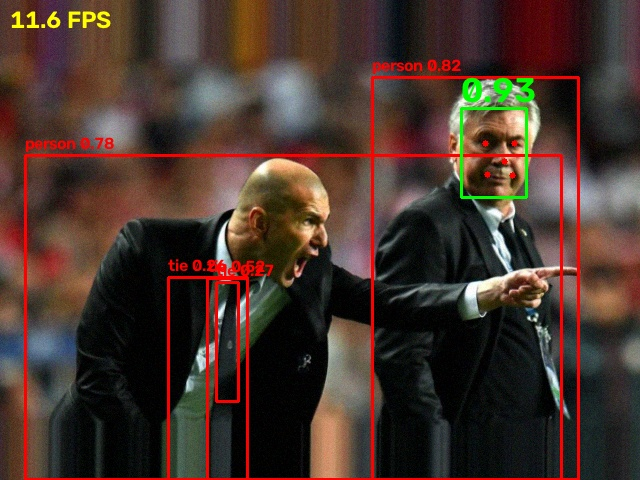

Frame source: SIMULATED stream (no webcam found) — photo with camera motion + sensor noise


Integrated pipeline (YuNet = green, YOLOv8n = red): 100 frames processed, average 11.6 FPS


In [20]:
def morph_clean(img, k=3):
    '''Light morphological opening (3×3 ellipse) to suppress small bright noise specks.'''
    return cv2.morphologyEx(img, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))

def draw_yolo(img, res, color=(0, 0, 255)):
    '''Red boxes with "class confidence" labels.'''
    out = img.copy()
    for (x1, y1, x2, y2), c, s in zip(res.boxes.xyxy.cpu().numpy().astype(int), res.boxes.cls.cpu().numpy().astype(int), res.boxes.conf.cpu().numpy()):
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
        cv2.putText(out, f"{res.names[c]} {s:.2f}", (x1, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return out

def pipeline(frame, faces=True, objects=True, clean=False):
    '''Per frame: optional morphological pre-clean → YOLO objects (red) → YuNet faces (green) on one output frame.'''
    src = morph_clean(frame) if clean else frame
    out = src.copy()
    if objects:
        out = draw_yolo(out, yolo_detect(src))
    if faces:
        out = draw_faces(out, detect_faces(face_det, src))
    return out

fps_pipeline_live = run_stream(pipeline, "Integrated pipeline (YuNet = green, YOLOv8n = red)", save="integrated_pipeline.png")

## 5.2 Morphological pre-cleaning
Salt-and-pepper noise (4 %) is added to three photos to mimic a noisy camera frame. Both detectors are run on the clean image, the noisy image, and the noisy image after a light morphological opening. For each: number of faces, number of YOLO objects and mean YOLO confidence.

image         variant             faces  objects  mean conf
zidane.jpg    clean                   1        3       0.65


zidane.jpg    noisy                   1        3       0.51
zidane.jpg    noisy + opening         1        2       0.83


bus.jpg       clean                   2        5       0.73
bus.jpg       noisy                   0        5       0.56


bus.jpg       noisy + opening         1        5       0.72
street.png    clean                   0        6       0.66


street.png    noisy                   0        6       0.52
street.png    noisy + opening         0        6       0.62


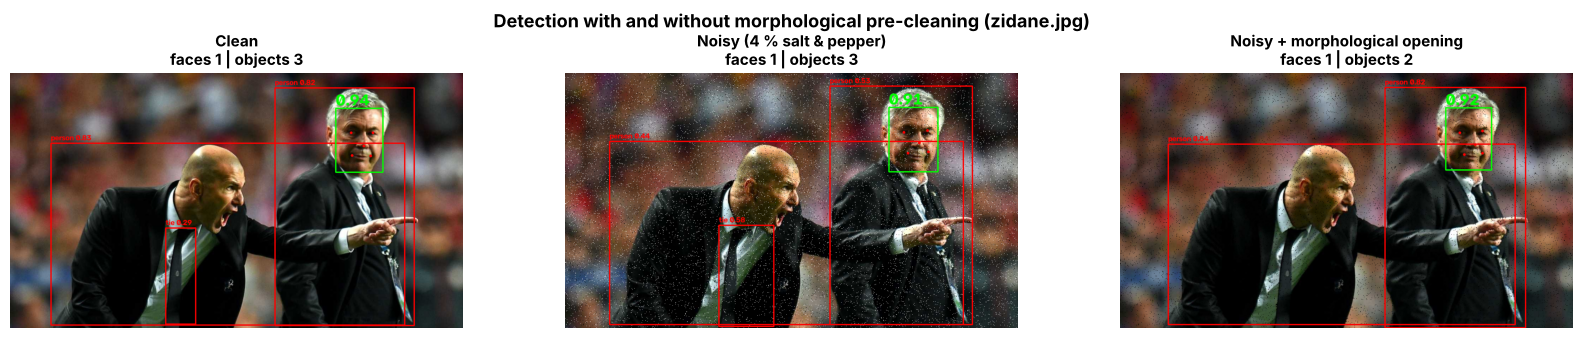

In [21]:
def quality(img):
    conf = yolo_detect(img).boxes.conf.cpu().numpy()
    return len(detect_faces(face_det, img)), len(conf), float(conf.mean()) if len(conf) else 0.0

NOISE_IMAGES = ["zidane.jpg", "bus.jpg", "street.png"]
print(f"{'image':14s}{'variant':18s}{'faces':>7s}{'objects':>9s}{'mean conf':>11s}")
for name in NOISE_IMAGES:
    img = load(name)
    noisy_img = add_salt_pepper(img, 0.04, seed=1)
    for variant, im in (("clean", img), ("noisy", noisy_img), ("noisy + opening", morph_clean(noisy_img))):
        f, o, c = quality(im)
        print(f"{name:14s}{variant:18s}{f:>7d}{o:>9d}{c:>11.2f}")

demo = load("zidane.jpg")
demo_noisy = add_salt_pepper(demo, 0.04, seed=1)
variants = {"Clean": demo, "Noisy (4 % salt & pepper)": demo_noisy, "Noisy + morphological opening": morph_clean(demo_noisy)}
grid([pipeline(im) for im in variants.values()],
     [f"{k}\nfaces {quality(im)[0]} | objects {quality(im)[1]}" for k, im in variants.items()], 1, 3,
     "morph_preclean_comparison.png", suptitle="Detection with and without morphological pre-cleaning (zidane.jpg)", cell=(5.6, 3.4))

**Observation.** Salt-and-pepper noise lowers YOLO's mean confidence on every image (zidane 0.65 → 0.51, bus 0.73 → 0.56, street 0.66 → 0.52) and made YuNet lose both faces in `bus.jpg` (2 → 0). A light 3×3 opening recovers most of it: bus faces return to 1 and mean confidence rises to 0.72 (clean: 0.73), street to 0.62, zidane to 0.83. It is not free: opening also removes some real small detail (in `zidane` the tie was lost, 3 → 2 objects, so that 0.83 is averaged over fewer objects), and it only suppresses *bright* specks, not dark ones. Conclusion: a cheap opening helps on genuinely noisy frames, but should not be applied to clean frames.

## 5.3 FPS benchmarking
The **same 100 frames** are captured once and every configuration is timed on them (3 warm-up frames excluded).

Frame source: SIMULATED stream (no webcam found) — photo with camera motion + sensor noise


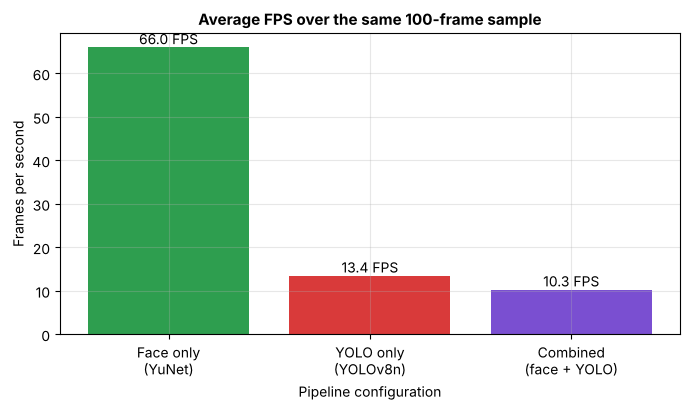

In [22]:
def benchmark(fn, frames, warmup=3):
    '''Average FPS of fn over the given frames.'''
    for f in frames[:warmup]:
        fn(f)
    t0 = time.perf_counter()
    for f in frames:
        fn(f)
    return len(frames) / (time.perf_counter() - t0)

sample = list(stream(N_FRAMES))
fps = {"Face only\n(YuNet)":  benchmark(lambda f: pipeline(f, objects=False), sample),
       "YOLO only\n(YOLOv8n)": benchmark(lambda f: pipeline(f, faces=False), sample),
       "Combined\n(face + YOLO)": benchmark(pipeline, sample)}

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(list(fps), list(fps.values()), color=["#2e9e4f", "#d93a3a", "#7a4fd1"])
ax.bar_label(bars, fmt="%.1f FPS")
ax.set(title=f"Average FPS over the same {len(sample)}-frame sample", xlabel="Pipeline configuration", ylabel="Frames per second")
finish(fig, "fps_comparison.png")

## 5.4 Final results comparison table
Approximate FPS of the classical techniques is measured on the same 100-frame sample (per-frame cost of the operation alone).

| Technique | Type | What it detects / does | Lighting robustness | Approx. FPS | Best use case |
|---|---|---|---|---|---|
| Morphology (erode / dilate / open / close) | Classical | Cleans binary masks: removes specks, fills holes | Low — depends on the threshold that made the mask | 3417 | Denoising foreground masks before a detector or blob finder |
| Bitwise operations (AND / OR / XOR / NOT) | Classical | Combines masks and images, extracts ROIs | N/A — inherits the quality of the masks | 6037 | ROI extraction, watermarking, privacy masks |
| Histograms + brightness / contrast | Classical | Measures exposure and contrast (no objects) | Diagnostic — reveals lighting problems | 1018 | Checking / correcting frames before detection |
| YuNet face detector | Deep learning | Faces + 5 landmarks + confidence | Medium–high (trained on in-the-wild faces) | 66.0 | Real-time face detection, anonymisation, tagging |
| YOLOv8n object detector | Deep learning | 80 COCO classes (person, car, dog …) | High (learned features), degrades in very dark scenes | 13.4 | General real-time object detection on edge / CPU |

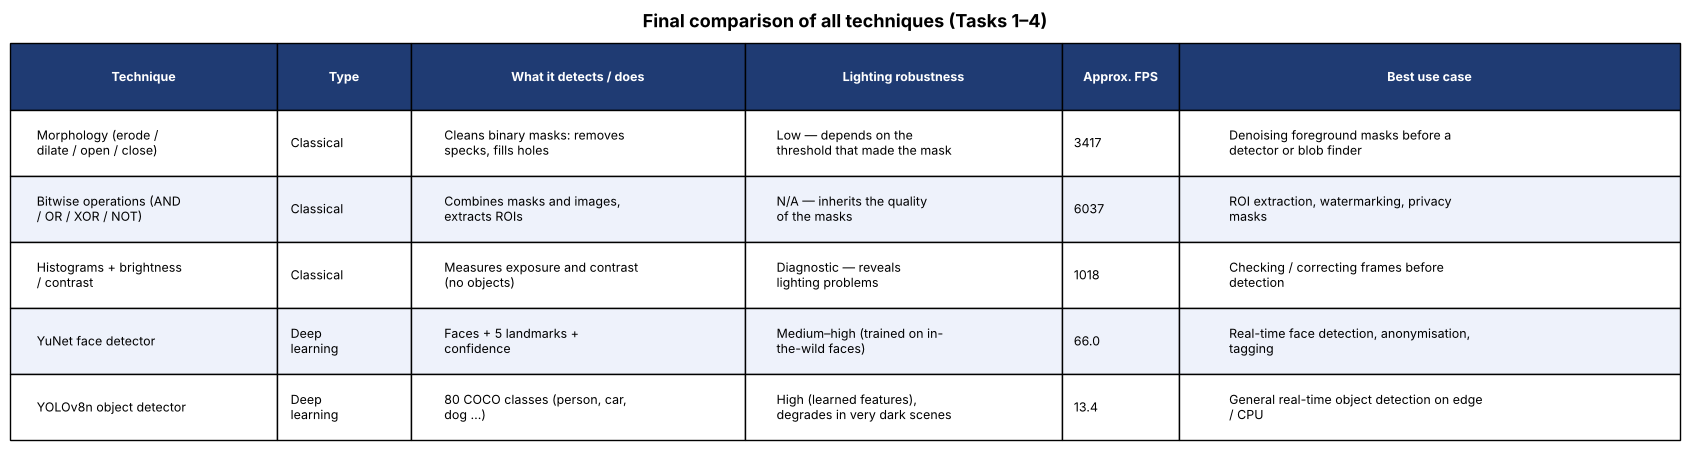

In [23]:
import textwrap
mask = cv2.circle(np.zeros(sample[0].shape[:2], np.uint8), (320, 240), 150, 255, -1)
classical_fps = {
    "morph":  benchmark(lambda f: cv2.morphologyEx(f, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)), sample),
    "bitwise": benchmark(lambda f: cv2.bitwise_and(f, f, mask=mask), sample),
    "hist":   benchmark(lambda f: [cv2.calcHist([f], [i], None, [256], [0, 256]) for i in range(3)], sample)}
face_fps, yolo_fps = list(fps.values())[:2]

header = ["Technique", "Type", "What it detects / does", "Lighting robustness", "Approx. FPS", "Best use case"]
rows = [
    ["Morphology (erode / dilate / open / close)", "Classical", "Cleans binary masks: removes specks, fills holes", "Low — depends on the threshold that made the mask", f"{classical_fps['morph']:.0f}", "Denoising foreground masks before a detector or blob finder"],
    ["Bitwise operations (AND / OR / XOR / NOT)", "Classical", "Combines masks and images, extracts ROIs", "N/A — inherits the quality of the masks", f"{classical_fps['bitwise']:.0f}", "ROI extraction, watermarking, privacy masks"],
    ["Histograms + brightness / contrast", "Classical", "Measures exposure and contrast (no objects)", "Diagnostic — reveals lighting problems", f"{classical_fps['hist']:.0f}", "Checking / correcting frames before detection"],
    ["YuNet face detector", "Deep learning", "Faces + 5 landmarks + confidence", "Medium–high (trained on in-the-wild faces)", f"{face_fps:.1f}", "Real-time face detection, anonymisation, tagging"],
    ["YOLOv8n object detector", "Deep learning", "80 COCO classes (person, car, dog …)", "High (learned features), degrades in very dark scenes", f"{yolo_fps:.1f}", "General real-time object detection on edge / CPU"]]

display(Markdown("| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n" + "\n".join("| " + " | ".join(r) + " |" for r in rows)))

fig, ax = plt.subplots(figsize=(17, 4.6))
ax.axis("off")
widths = [0.16, 0.08, 0.20, 0.19, 0.07, 0.30]
tbl = ax.table(cellText=[[textwrap.fill(c, w) for c, w in zip(r, (24, 10, 30, 28, 8, 42))] for r in rows], colLabels=header,
               colWidths=widths, loc="center", cellLoc="left")
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 3.6)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor("#1f3b73"); cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#eef2fb")
ax.set_title("Final comparison of all techniques (Tasks 1–4)", fontweight="bold", fontsize=13, pad=14)
finish(fig, "results_table.png")

## 5.5 Reflection
**Best accuracy-to-compute trade-off.** For real-time monitoring the best combination was a **light morphological opening (only when the frame is noisy) + YuNet + YOLOv8n**. The classical steps cost almost nothing (thousands of FPS in the table) yet recovered a large part of the accuracy lost to noise; YuNet is cheap and adds landmarks and faces that YOLO's `person` class cannot give; YOLOv8n adds 80 object classes. The FPS chart shows the real price: the combined pipeline is slower than either detector alone, and YOLO dominates the cost, so any speed-up should target YOLO first.

**If deployed on a low-power edge device** (e.g. Raspberry Pi, Jetson Nano): keep `yolov8n` (or export it to ONNX/TensorRT/INT8), reduce the input size, run YOLO on every 2nd–3rd frame while YuNet runs every frame, use a high YuNet threshold (≈ 0.9) to avoid false alarms, and keep the cheap opening only for noisy cameras.

**If deployed on a cloud server / GPU:** swap to `yolov8s` or `yolov8m` for higher accuracy on small and occluded objects, lower the YuNet threshold (≈ 0.6–0.7) to catch profile and small faces, and drop the pre-cleaning because a bigger model is more noise-tolerant and compute is no longer the bottleneck.